# AR · Де пожежі повторюються на тих самих місцях?

**Тип:** виміряно. **Навіщо:** Чи повторюються пожежі на тих самих місцях настільки, щоб контури минулих подій передбачали нові.

Цей ноутбук повторює блок сторінки досліджень `web/science/#ar` і бере ті самі результати.

In [1]:
import sys
sys.path.insert(0, '..')
import pandas as pd
from eaglewings.ds import report
pd.set_option('display.width', 200)
%matplotlib inline

## Постановка, дані, протокол і метрики

Текст узято з модуля задачі, той самий записується в журнал кожного запуску.

In [2]:
print(report.protocol('AR'))

AR · Ареалізація появи на реальних пожежах Греції: чи падають нові пожежі в ареали, побудовані за минулими роками.

Задача      ареал має показувати, де подія повторюється. Перевіряємо це на реальних даних, а не на потоці демо.
Дані        NASA FIRMS (VIIRS + MODIS), Греція, 2021–2025: точки зведені в пожежі правилом FM (2 км, 5 діб). Одиниця — гекс H3 res 7.
Протокол    для року Y ареали будуються лише з пожеж років Y−W…Y−1. Вибір радіуса й вікна на 2023, тест на 2024 і 2025. Усі методи отримують рівно ту саму площу: 1,5 % гексів.
Метрики     PAI: у скільки разів щільність нових пожеж у зоні вища за середню. Також частка нових пожеж у зоні. CI — bootstrap по блоках H3 res 4.
Підходи
  arealization  DBSCAN за центрами минулих пожеж + опукла оболонка: зрозумілі контури
  history       гекси, де вже горіло
  kde           згладжена щільність минулих пожеж
  random        випадкові гекси: PAI ≈ 1
Парки       ареали будуються по всій Греції; для кожного парку дослідження (ds/regions.py) ок

## Результат

Обраний підхід виділено. Вибір робився лише на валідації, числа тут з тесту.

,approach,val_pai,test_pai,lo,hi,test_capture
0,ареалізація,15.23,17.52,11.85,22.26,0.26
1,історія,16.59,18.66,12.83,24.25,0.28
2,KDE,11.79,12.39,5.03,18.61,0.19
3,випадково,0.82,1.50,0.79,2.47,0.02


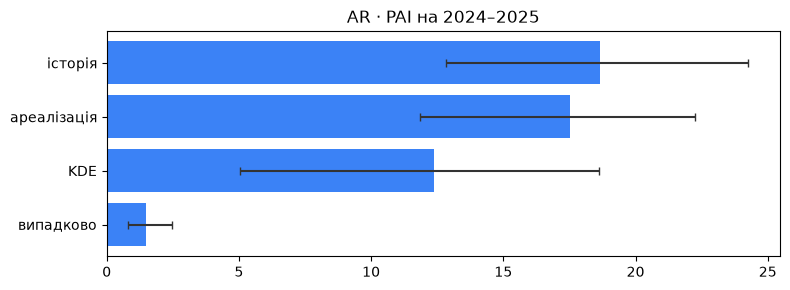

In [3]:
table, fig = report.show('AR')
table